# Laboratory Exercise 3 — Bayesian Networks

## Email Spam Classification

This exercise uses a Bayesian Network to classify emails as spam or non-spam based on three observed characteristics:

- **S:** Whether the email is spam (1) or not spam (0).
- **O:** Whether the email contains the word "offer" (1) or not (0).
- **L:** Whether the email contains links (1) or not (0).
- **M:** Whether the email is long (1) or not (0).

The exercise consists of two parts:

**a)** Identify the conditional independencies in the Bayesian Network.

**b)** Determine how the network classifies emails based on O, L and M.

In [21]:
%pip install pgmpy networkx matplotlib pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

from itertools import product
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

## Bayesian Network Structure

The network has the following dependencies:

- Spam (S) influences the presence of the word "offer" (O).
- Spam (S) influences the presence of links (L).
- Spam (S) and links (L) influence the email length (M).

Therefore, the directed edges are:

- S → O
- S → L
- S → M
- L → M

The joint probability distribution is:

$$
P(S,O,L,M)=P(S)P(O\mid S)P(L\mid S)P(M\mid S,L)
$$

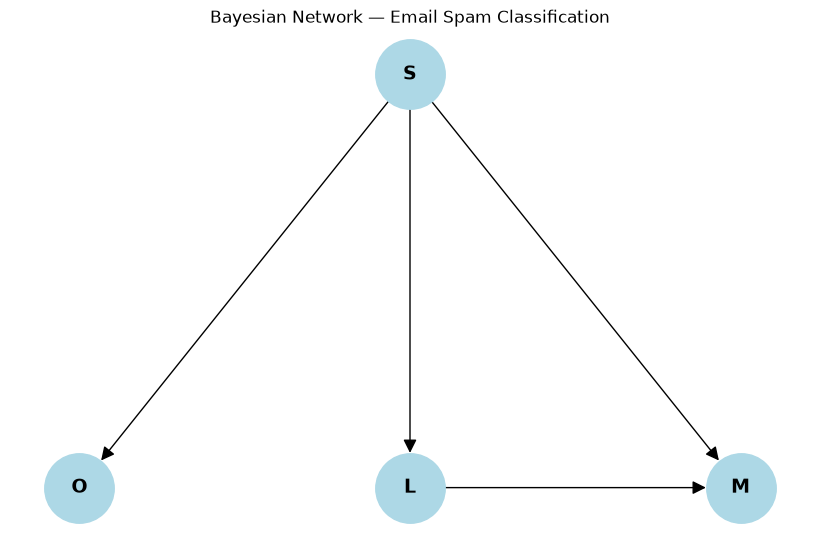

In [23]:
# Define the Bayesian Network
model = DiscreteBayesianNetwork([
    ("S", "O"),
    ("S", "L"),
    ("S", "M"),
    ("L", "M")
])

# Draw the network
pos = {
    "S": (0, 2),
    "O": (-1.5, 0),
    "L": (0, 0),
    "M": (1.5, 0)
}

plt.figure(figsize=(8, 5))

nx.draw(
    model,
    pos=pos,
    with_labels=True,
    node_color="lightblue",
    node_size=2500,
    font_size=14,
    font_weight="bold",
    arrows=True,
    arrowsize=20
)

plt.title("Bayesian Network — Email Spam Classification")
plt.show()

## Conditional Probability Tables (CPDs)

The probabilities are provided in the exercise.

### Spam probabilities

$$
P(S=0)=0.6,\qquad P(S=1)=0.4
$$

### Word "offer"

| | S = 0 | S = 1 |
|---|---:|---:|
| O = 0 | 0.9 | 0.3 |
| O = 1 | 0.1 | 0.7 |

### Links

| | S = 0 | S = 1 |
|---|---:|---:|
| L = 0 | 0.7 | 0.2 |
| L = 1 | 0.3 | 0.8 |

### Email length

| | S=0, L=0 | S=0, L=1 | S=1, L=0 | S=1, L=1 |
|---|---:|---:|---:|---:|
| M = 0 | 0.8 | 0.4 | 0.5 | 0.1 |
| M = 1 | 0.2 | 0.6 | 0.5 | 0.9 |

In [24]:
# Spam probabilities
cpd_s = TabularCPD(
    variable="S",
    variable_card=2,
    values=[[0.6], [0.4]]
)

# Probability of containing the word "offer"
cpd_o = TabularCPD(
    variable="O",
    variable_card=2,
    values=[
        [0.9, 0.3],
        [0.1, 0.7]
    ],
    evidence=["S"],
    evidence_card=[2]
)

# Probability of containing links
cpd_l = TabularCPD(
    variable="L",
    variable_card=2,
    values=[
        [0.7, 0.2],
        [0.3, 0.8]
    ],
    evidence=["S"],
    evidence_card=[2]
)

# Probability of having a long email
cpd_m = TabularCPD(
    variable="M",
    variable_card=2,
    values=[
        [0.8, 0.4, 0.5, 0.1],
        [0.2, 0.6, 0.5, 0.9]
    ],
    evidence=["S", "L"],
    evidence_card=[2, 2]
)

# Add the probability tables to the model
model.add_cpds(cpd_s, cpd_o, cpd_l, cpd_m)

# Check that the model is valid
print("Model is valid:", model.check_model())

Model is valid: True


## Part A — Conditional Independencies

The Bayesian Network follows the structure:

$$
S \rightarrow O,\quad S \rightarrow L,\quad S \rightarrow M,\quad L \rightarrow M
$$

Using the local Markov property and d-separation, we can identify the following conditional independencies.

### 1. O and L are conditionally independent given S

$$
O \perp L \mid S
$$

Once we know whether an email is spam, knowing whether it contains links does not provide additional information about the presence of the word "offer".

### 2. O and M are conditionally independent given S

$$
O \perp M \mid S
$$

Once the spam status is known, the presence of the word "offer" does not provide additional information about the email length.

### Conclusion

The main conditional independencies are:

$$
\boxed{O \perp L \mid S}
$$

$$
\boxed{O \perp M \mid S}
$$

These relationships follow from the structure of the Bayesian Network.

In [25]:
# Display the local independencies of the network
print("Local independencies:")
print(model.local_independencies(["S", "O", "L", "M"]))

# Check the conditional independencies
print("\nO independent of L given S:",
      model.is_dconnected("O", "L", observed=["S"]) == False)

print("O independent of M given S:",
      model.is_dconnected("O", "M", observed=["S"]) == False)

Local independencies:
(L ⟂ O | S)
(M ⟂ O | L, S)
(O ⟂ L, M | S)

O independent of L given S: True
O independent of M given S: True


## Part B — Email Classification

The goal is to calculate the probability that an email is spam given the observed values of O, L and M.

We need to calculate:

$$
P(S=1\mid O=o,L=l,M=m)
$$

Using Bayes' theorem and the factorization of the network:

$$
P(S=1\mid o,l,m)=
\frac{
P(S=1)P(o\mid S=1)P(l\mid S=1)P(m\mid S=1,l)
}{
\sum_{s=0}^{1}P(S=s)P(o\mid S=s)P(l\mid S=s)P(m\mid S=s,l)
}
$$

We classify an email as:

- **Spam** if $P(S=1\mid O,L,M)>0.5$.
- **Not Spam** if $P(S=1\mid O,L,M)<0.5$.

We use `VariableElimination` from `pgmpy` to calculate these probabilities.

In [26]:
# Create the inference model
inference = VariableElimination(model)

# Example: email contains "offer", links and is long
result = inference.query(
    variables=["S"],
    evidence={"O": 1, "L": 1, "M": 1}
)

print(result)

# Extract the spam probability
spam_probability = result.values[1]

print("\nSpam probability:", spam_probability)

if spam_probability > 0.5:
    print("Classification: Spam")
else:
    print("Classification: Not Spam")

+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.0508 |
+------+----------+
| S(1) |   0.9492 |
+------+----------+

Spam probability: 0.9491525423728814
Classification: Spam


### Classification of all possible emails

Since O, L and M are binary variables, there are 8 possible combinations.

We calculate the probability of spam for each combination using Bayesian inference.

An email is classified as Spam if the probability is greater than 0.5. Otherwise, it is classified as Not Spam.

In [27]:
# Classify all possible combinations of email characteristics
results = []

for o, l, m in product([0, 1], repeat=3):

    # Calculate the probability of spam
    result = inference.query(
        variables=["S"],
        evidence={"O": o, "L": l, "M": m},
        show_progress=False
    )

    spam_probability = result.values[1]

    # Classify the email
    if spam_probability > 0.5:
        classification = "Spam"
    else:
        classification = "Not Spam"

    results.append({
        "O": o,
        "L": l,
        "M": m,
        "P(Spam)": round(spam_probability, 4),
        "Classification": classification
    })

# Display the results
df = pd.DataFrame(results)
print(df.to_string(index=False))

 O  L  M  P(Spam) Classification
 0  0  0   0.0382       Not Spam
 0  0  1   0.1370       Not Spam
 0  1  0   0.1290       Not Spam
 0  1  1   0.4706       Not Spam
 1  0  0   0.4545       Not Spam
 1  0  1   0.7692           Spam
 1  1  0   0.7568           Spam
 1  1  1   0.9492           Spam


## Conclusion

In this exercise, we created a Bayesian Network to classify emails as spam or non-spam.

In Part A, we identified the conditional independencies using the structure of the network.

In Part B, we used Bayesian inference to calculate the probability of spam based on the observed characteristics O, L and M.

The network classifies emails by comparing the posterior probability of spam with a threshold of 0.5.